# ARMA, ARIMA and SARIMA Models

ARIMA$(p,d,q)$ applies ARMA dynamics to the $d$-times differenced series, and SARIMA adds seasonal differencing and seasonal AR/MA polynomials. This notebook checks the ARMA(1,1) autocorrelations from the note, shows differencing and over-differencing, fits an ARIMA model with diagnostics, and builds a seasonal forecast.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.arima_process import ArmaProcess, arma_acf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

rng = np.random.default_rng(40)

# ARMA(1,1): phi=0.7, theta=0.2 -- closed form vs statsmodels vs simulation
phi, theta = 0.7, 0.2
rho1 = (phi + theta) * (1 + phi * theta) / (1 + 2 * phi * theta + theta**2)
theory = [1, rho1] + [phi ** (k - 1) * rho1 for k in range(2, 6)]
print("closed form :", np.round(theory, 4))
print("statsmodels :", np.round(arma_acf([1, -phi], [1, theta], lags=6), 4))

proc = ArmaProcess(ar=[1, -phi], ma=[1, theta])
sim = proc.generate_sample(200000, distrvs=rng.standard_normal)
s = sim - sim.mean()
print("simulated   :", np.round([np.sum(s[k:] * s[:len(s) - k]) / np.sum(s * s) for k in range(6)], 4))

closed form : [1.     0.7773 0.5441 0.3809 0.2666 0.1866]
statsmodels : [1.     0.7773 0.5441 0.3809 0.2666 0.1866]
simulated   : [1.     0.7764 0.5423 0.3786 0.2645 0.1842]


All three agree: $\rho_1\approx0.777$, $\rho_2\approx0.544$, $\rho_3\approx0.381$. The geometric decay at rate $\phi$ starts from lag 1.

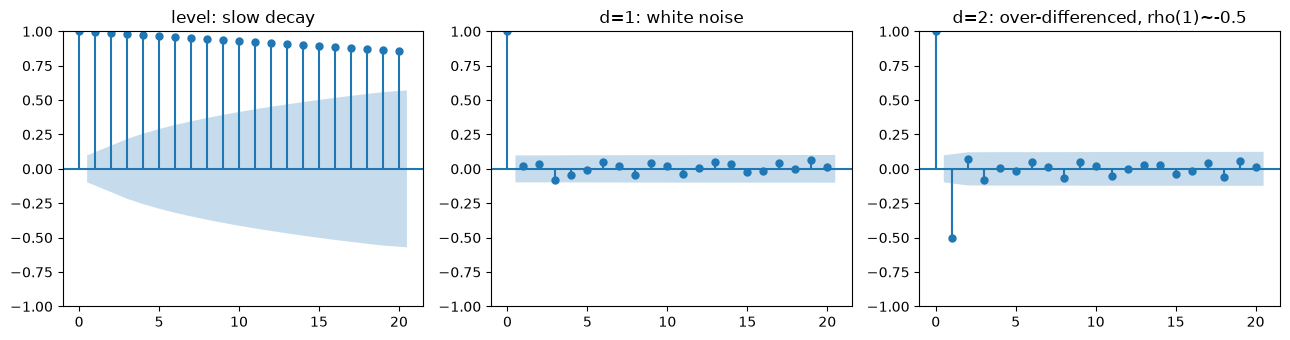

Var by d: 1412.0 1.02 2.0 (second difference ~ 2*sigma^2)


In [2]:
# Differencing a random walk with drift, and over-differencing
n = 400
rw = np.cumsum(0.2 + rng.normal(size=n))
d1, d2 = np.diff(rw), np.diff(rw, n=2)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
plot_acf(rw, lags=20, ax=ax[0]); ax[0].set_title("level: slow decay")
plot_acf(d1, lags=20, ax=ax[1]); ax[1].set_title("d=1: white noise")
plot_acf(d2, lags=20, ax=ax[2]); ax[2].set_title("d=2: over-differenced, rho(1)~-0.5")
plt.tight_layout(); plt.show()
print("Var by d:", rw.var().round(1), d1.var().round(2), d2.var().round(2), "(second difference ~ 2*sigma^2)")

One difference makes the walk white noise. A second difference yields $\varepsilon_t-\varepsilon_{t-1}$, with variance $2\sigma^2$ and lag-1 autocorrelation $-0.5$: the signature of over-differencing.

In [3]:
# Fit ARIMA(1,1,1) to a simulated integrated ARMA(1,1) and check residuals
arma = ArmaProcess(ar=[1, -0.6], ma=[1, 0.4]).generate_sample(600, distrvs=rng.standard_normal)
level = np.cumsum(arma)
fit = ARIMA(level, order=(1, 1, 1)).fit()
print(fit.params.round(3), "(true phi=0.6, theta=0.4)")
print("AIC:", round(fit.aic, 1), " BIC:", round(fit.bic, 1))
print(acorr_ljungbox(fit.resid[1:], lags=[10, 20]).round(3))

# AIC arithmetic from the note: -2 logL + 2k
print("AIC check:", 2 * 120 + 2 * 3, 2 * 116 + 2 * 4)

[0.525 0.452 0.993] (true phi=0.6, theta=0.4)
AIC: 1702.5  BIC: 1715.7
    lb_stat  lb_pvalue
10   10.490      0.399
20   13.623      0.849
AIC check: 246 240


The estimates recover the true AR and MA coefficients and the Ljung-Box p-values are large, so no residual autocorrelation remains. (The first residual of a differenced model is an initialization artefact, hence the `[1:]`.)

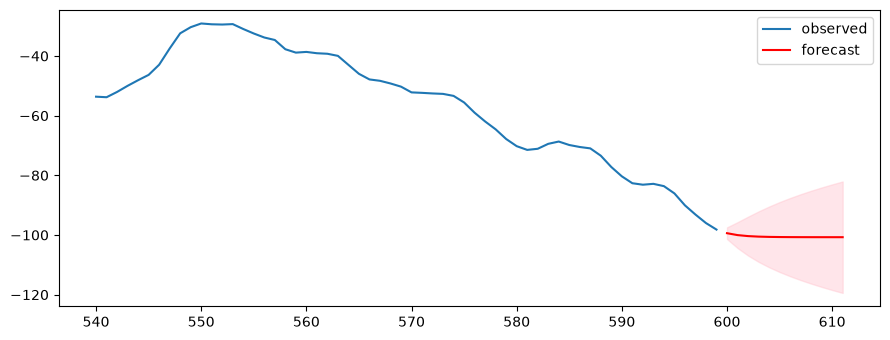

interval width h=1 vs h=12: 3.91 37.35


In [4]:
# Forecasts from differences must be integrated back to levels
fc = fit.get_forecast(12)
mean, ci = fc.predicted_mean, fc.conf_int()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(range(540, 600), level[540:], label="observed")
ax.plot(range(600, 612), mean, "r", label="forecast")
ax.fill_between(range(600, 612), ci[:, 0], ci[:, 1], color="pink", alpha=0.4)
ax.legend(); plt.tight_layout(); plt.show()
print("interval width h=1 vs h=12:", round(ci[0, 1] - ci[0, 0], 2), round(ci[-1, 1] - ci[-1, 0], 2))

Because the model contains a unit root, the interval widens without bound as the horizon grows — uncertainty accumulates when differenced forecasts are cumulated.

In [5]:
# Seasonal ARIMA(0,1,1)(0,1,1)_12 on a log-additive seasonal series
t = np.arange(180)
y = 50 + 0.15 * t + 6 * np.sin(2 * np.pi * t / 12) + np.cumsum(rng.normal(scale=0.3, size=180)) + rng.normal(scale=0.8, size=180)
train, test = y[:168], y[168:]
m = SARIMAX(train, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
pred = m.get_forecast(12).predicted_mean
naive = train[-12:]                                  # seasonal naive benchmark
rmse = lambda a, b: np.sqrt(np.mean((a - b) ** 2))
print("SARIMA RMSE:", rmse(test, pred).round(3), " seasonal-naive RMSE:", rmse(test, naive).round(3))

# check the combined difference identity (1-B)(1-B^12)
direct = y[13:] - y[12:-1] - y[1:-12] + y[:-13]
print("combined difference matches:", np.allclose(direct, np.diff(y[12:] - y[:-12])))

SARIMA RMSE: 0.984  seasonal-naive RMSE: 1.986
combined difference matches: True


The seasonal-naive forecast is the benchmark any SARIMA model must beat; the final check confirms the four-term expansion $y_t-y_{t-1}-y_{t-12}+y_{t-13}$ used in the note.